# 路线二 · 线性收缩边界

正式实验 Matching 任务中，加入线性收缩边界后，能否更准确地预测截止前有效作答的选择和慢反应？

固定和收缩模型沿用 M2 的试次划分和条件结构，共用作答窗口、层级先验和首达时间似然。固定模型令收缩角为零，收缩模型估计一个全体共享的收缩角。主比较为留出试次的联合对数预测密度，同时报告 P90 和 Match 选择率。

运行内核为 Python (HSSM · NumPyro GPU)，工作目录为 scripts/，正式结果写入 ../outputs/collapsing/m2_centered_ndt/。

[2020 年原实验](https://doi.org/10.1525/collabra.301) · [Leng 等人的线性边界模型](https://doi.org/10.1371/journal.pcbi.1014667) · [路线一 · Lévy 证据跳跃](03_levy_flight_bayesflow.ipynb)

## 1. 正式实验 Matching 试次与作答窗口

沿用 M2 的有效 Match / Mismatch 作答和分层留出划分。原始数据中的 ACC = −1 表示截止前无按键，ACC = 2 表示无效键。两类记录均在生成建模输入时排除。

实验从刺激出现计 RT，刺激呈现 0.100 秒后开始检测按键。作者程序在每位被试开始时设定空屏时长，截止时停止检测。原始 CSV 没有单独存储截止时间。用每位被试超时试次最后一次检测时间的中位数估计截止，并用实验设定的 0.100 秒作为窗口起点。超时记录用于估计截止。最短有效 RT 集中在 0.106 秒附近，程序在窗口打开后首次读取按键；这些试次保留进入分析。

stim_sign 为刺激实际匹配状态，response 为实际选择，两列分别使用 +1 和 −1。

[作者的刺激时长设置](https://github.com/hcp4715/moralSelf_ddm/blob/master/2_confirm_study/Procedure/confirmStudy_proc/Moral_self_asso_exp7_rep_getParams.m#L162-L171) · [按键与时间记录](https://github.com/hcp4715/moralSelf_ddm/blob/master/2_confirm_study/Procedure/confirmStudy_proc/Moral_self_asso_exp7_rep_match.m#L224-L266) · [HDDM 输入预处理](../../01_reproduction_2020/scripts/01_behavior.R)

In [1]:
# 导入 HSSM、采样诊断与绘图库。
from pathlib import Path

import arviz_stats as azs
import jax
import jax.numpy as jnp
import hssm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import xarray as xr
from IPython.display import display
from jax.scipy.special import logsumexp as jax_logsumexp
from scipy.optimize import brentq
from scipy.special import expit, log_expit, logit, logsumexp

# 复用 M2 的试次划分种子。首达时间密度和积分使用双精度。
seed = 2026
max_tree_depth = 10
score_batch_size = 16
hssm.set_floatX("float64", update_jax=True)

# 直接读取第二部分 M2 的 Matching 建模输入。
outputs = Path("../outputs/collapsing/m2_centered_ndt")
trials = pd.read_csv("../../01_reproduction_2020/data/derived/matching_hddm.csv")
trials = trials.rename(columns={"subj_idx": "participant_id"})

# 实际匹配的刺激记为 +1，按 Match 也记为 +1。答错时这两列符号相反。
trials["stim_sign"] = 2 * trials["stim"] - 1
trials["response"] = 2 * trials["response"] - 1
# 四种形状各有实际匹配、不匹配两种刺激，分别对应 M2 的八个漂移条件。
shape_order = ["Good-self", "Bad-self", "Good-other", "Bad-other"]
trials["shape"] = (trials["val"] + "-" + trials["id"].str.lower()).astype("category")
trials["trial_condition"] = (trials["match"] + "_" + trials["shape"].astype(str)).astype("category")

# 根据原实验记录，为每位保留被试估计键盘检测截止时间。
raw_path = Path("../../01_reproduction_2020/data/raw/MS_rep_matchingTask_raw.csv")
raw = pd.read_csv(raw_path, usecols=["Subject", "Prac", "ACC", "RT"])
timeouts = raw.loc[raw["Prac"].eq("Exp") & raw["ACC"].eq(-1)]
deadlines = timeouts.groupby("Subject")["RT"].median()
trials["window_open"] = 0.100
trials["deadline"] = trials["participant_id"].map(deadlines)
if not trials["rt"].between(trials["window_open"], trials["deadline"]).all():
    raise ValueError("有效作答超出估计窗口，请核对原始 RT 与按键时间。")

# 沿用 M2 的分层、种子及行序，使两种边界模型使用同一批试次。
strata = ["participant_id", "match", "val", "id"]
heldout_index = trials.groupby(strata).sample(frac=0.2, random_state=seed).index
fit_trials = trials.drop(index=heldout_index).reset_index(drop=True)
heldout_trials = trials.loc[heldout_index].reset_index(drop=True)

# 每个被试 × 试次条件共享一组参数和一个作答窗口。
cell_keys = ["participant_id", "trial_condition"]
first_trial = np.flatnonzero(~fit_trials.duplicated(cell_keys))
parameter_cells = fit_trials.iloc[first_trial].reset_index(drop=True)
cell_positions = pd.Series(
    parameter_cells.index.to_numpy(), index=pd.MultiIndex.from_frame(parameter_cells[cell_keys]),
)

# 表中列出被试数、试次数与超时记录数。
display(pd.Series({
    "subjects": trials["participant_id"].nunique(),
    "fit": len(fit_trials), "held_out": len(heldout_trials),
    "timeouts": timeouts["Subject"].isin(trials["participant_id"]).sum(),
}, name="count"))

subjects       42
fit         19599
held_out     4929
timeouts      649
Name: count, dtype: int64

## 2. M2 的条件结构与路线二的层级先验

| 参数 | 组层位置 | 被试偏移 | 组层位置先验 |
| --- | --- | --- | --- |
| \(v\) 漂移率 | 八种试次条件 | 被试 × 试次条件 | Uniform (−3, 3) |
| \(a\) 初始边界半间距 | 跨条件共享 | 被试 | Uniform (0.30, 3) |
| \(z\) 起点比例 | 四种形状 | 被试 × 形状 | 链接尺度 Normal (0, 0.25) |
| \(t\) 非决策时间 | 八种试次条件 | 被试 × 试次条件 | 秒尺度中位数 0.22，链接尺度标准差 0.65 |

\(v\) 的组层位置与被试偏移共同乘以刺激符号。\(z>0.5\) 表示起点靠近 Match。每类参数在各条件共享一个被试间标准差。被试偏移在链接尺度上服从零均值正态分布，标准差的 Weibull 先验形状为 1.5。\(v,a,z\) 的尺度为 0.3，\(t\) 的尺度为 0.55。

对被试 \(i\) 与条件 \(c\)，直接抽取个人位置 \(\eta_{ic}\sim\mathcal N(\mu_c,\sigma_t^2)\)，再换算为秒：\(t_{ic}=0.001+1.999\,\mathrm{logistic}(\eta_{ic})\)。\(\mu_c\) 是该条件的组基准，\(\sigma_t\) 是八个条件共用的被试间标准差。回归式中的个人偏移由 \(\eta_{ic}-\mu_c\) 算出。两种模型均要求 \(RT>t_{ic}\)。[第二部分 M2](../../02_reanalysis_2026/scripts/02_static_v_dc.ipynb) · [HSSM 有界先验](https://github.com/lnccbrown/HSSM/blob/v0.5.0/src/hssm/prior.py)

In [2]:
# 有界 logit 把系数映射回参数范围。标准 Logistic 先验使组层位置在原范围上均匀。
uniform_on_parameter = hssm.Prior("Logistic", mu=0, s=1)
nondecision_bounds = (0.001, 2.0)
t_lower, t_upper = nondecision_bounds
nondecision_center = logit((0.22 - t_lower) / (t_upper - t_lower))
nondecision_group = hssm.Prior("Normal", mu=nondecision_center, sigma=0.65)


def ndt_condition_indices(model, person_dim):
    # 按模型坐标把每个「被试:条件」对应到它的组基准。
    condition_dim = model.named_vars_to_dims["ndt_trial_condition"][0]
    conditions = list(model.coords[condition_dim])
    return [conditions.index(cell.split(":", 1)[1]) for cell in model.coords[person_dim]]


def centered_ndt_deviation(name, sigma, dims):
    # 直接抽个人位置，HSSM 回归使用它相对条件基准的差值。
    model = pm.modelcontext(None)
    condition = ndt_condition_indices(model, dims[0])
    baseline = model["ndt_trial_condition"][condition]
    person = pm.Normal("ndt_person_location", mu=baseline, sigma=sigma, dims=dims)
    return pm.Deterministic(name, person - baseline, dims=dims)


nondecision_deviation = hssm.Prior(
    "Normal", dist=centered_ndt_deviation, noncentered=False,
    sigma=hssm.Prior("Weibull", alpha=1.5, beta=0.55),
)

# 四类参数分别估计一个被试间标准差，每类内部的所有条件共用它。
participant_deviation = hssm.Prior(
    "Normal", mu=0, sigma=hssm.Prior("Weibull", alpha=1.5, beta=0.3),
)

# 公式中 0 + 去掉共同截距，竖线右侧指定个人偏移所属的分组。
shared_parameters = [
    # v 按八种条件估计，刺激符号同时作用于组层位置和被试偏移。
    {
        "name": "v",
        "formula": (
            "v ~ 0 + stim_sign:trial_condition"
            " + (0 + stim_sign | participant_id:trial_condition)"
        ),
        "prior": {
            "stim_sign:trial_condition": uniform_on_parameter,
            "group_specific": participant_deviation,
        },
    },
    # a 在所有条件间共享，每位被试有一个边界半间距。
    {
        "name": "a",
        "formula": "a ~ 1 + (1 | participant_id)",
        "prior": {
            "Intercept": uniform_on_parameter,
            "group_specific": participant_deviation,
        },
    },
    # z 按四种形状估计。同一形状共用相对起点，大于 0.5 时起点更靠近 Match。
    {
        "name": "z",
        "formula": "z ~ 0 + shape + (1 | participant_id:shape)",
        "prior": {"group_specific": participant_deviation},
    },
    # t 按八种条件估计，每位被试在每种条件下有一个非决策时间。
    {
        "name": "ndt",
        "formula": "ndt ~ 0 + trial_condition + (1 | participant_id:trial_condition)",
        "prior": {
            "trial_condition": nondecision_group,
            "group_specific": nondecision_deviation,
        },
        "bounds": nondecision_bounds,
    },
]

## 3. 固定边界与线性收缩边界

从证据积累开始 \(s\) 秒后，边界为 \(\pm (a-s\tan\theta)\)，初始位置为 \(a(2z-1)\)，扩散噪声尺度为 1。固定模型的 \(\theta=0\)。收缩模型的角度采用 Leng 等人补充表 A3 的 Uniform (0, 1.2) 弧度。

两种情形共用解析首达时间密度。线性边界用时间变换 \(s/[1-s\tan(\theta)/a]\) 化为固定边界，固定区间的密度用 Navarro–Fuss 的短时与长时级数计算。\(RT\le t\) 或边界闭合后的作答密度为零。

对每个被试与试次条件，把两侧密度在作答窗口内积分。用单次按键和 RT 的联合密度除以这个窗口内概率，得到「已在窗口内作答」的条件密度。拟合和留出评分调用同一个函数。

[PyDDM 的线性边界解析解](https://pyddm.readthedocs.io/en/latest/apidoc/model.html#pyddm.model.Model.solve_analytical) · [Navarro 与 Fuss 的 Wiener 首达时间级数](https://doi.org/10.1016/j.jmp.2009.02.003) · [Leng 等人的补充表 A3](https://journals.plos.org/ploscompbiol/article/file?id=10.1371/journal.pcbi.1014667.s001&type=supplementary)

In [3]:
# 单位边界间距、零漂移的首达密度。短时使用反射级数，长时使用正弦级数。
def zero_drift_log_density(time, distance):
    small_time = jnp.minimum(time, 0.15)
    distance = distance[..., None]
    reflections = distance + 2 * jnp.arange(-2, 3)
    small_terms = reflections * jnp.exp(
        -(reflections**2 - distance**2) / (2 * small_time[..., None])
    )
    early = (
        jnp.log(small_terms.sum(axis=-1))
        - distance[..., 0] ** 2 / (2 * small_time)
        - 1.5 * jnp.log(small_time)
        - 0.5 * jnp.log(2 * jnp.pi)
    )
    large_time = jnp.maximum(time, 0.15)
    modes = jnp.arange(1, 7)
    large_terms = modes * jnp.sin(jnp.pi * modes * distance) * jnp.exp(
        -0.5 * jnp.pi**2 * (modes**2 - 1) * large_time[..., None]
    )
    late = (
        jnp.log(jnp.pi * large_terms.sum(axis=-1))
        - 0.5 * jnp.pi**2 * large_time
    )
    return jnp.where(time < 0.15, early, late)


def angle_log_density(rt, choice, v, a, z, t, theta):
    """计算从刺激出现起计时的 RT 与所选边界的联合对数密度。"""
    elapsed = rt - t
    slope = jnp.tan(theta)
    scale = 1 - slope * elapsed / a
    supported = (elapsed > 0) & (scale > 0)
    elapsed = jnp.where(supported, elapsed, 1.0)
    scale = jnp.where(supported, scale, 1.0)

    # 把线性收缩区间变换为固定区间，时间变为 elapsed / scale。
    width = 2 * a
    x0 = width * (z - 0.5)
    boundary = choice * a * scale
    distance = jnp.where(choice == 1, 1 - z, z)
    drift_term = v * (boundary - x0) - 0.5 * v**2 * elapsed
    shrinkage_term = slope / (2 * a) * (a**2 * scale - x0**2)
    log_density = (
        zero_drift_log_density(elapsed / (scale * width**2), distance)
        - 2 * jnp.log(width)
        - 1.5 * jnp.log(scale)
        + shrinkage_term + drift_term
    )
    return jnp.where(supported, log_density, -jnp.inf)


# 用高斯–勒让德积分计算窗口内作答概率，两侧选择的密度都计入。
nodes, weights = np.polynomial.legendre.leggauss(64)
fractions = (nodes + 1) / 2
nodes = fractions**2
log_weights = np.log(weights * fractions)


def response_time_limits(window_open, deadline, a, t, theta):
    # 窗口从键盘开始记录和 t 中较晚的一刻开始，到截止或边界闭合时结束。
    slope = jnp.tan(theta)
    closure = t + a / jnp.where(slope > 0, slope, 1.0)
    start = jnp.maximum(window_open, t)
    end = jnp.where(slope > 0, jnp.minimum(deadline, closure), deadline)
    return start, end


def window_log_mass(window_open, deadline, v, a, z, t, theta):
    v, a, z, t = jnp.broadcast_arrays(v, a, z, t)
    start, end = response_time_limits(window_open, deadline, a, t, theta)
    duration = end - start
    valid = duration > 0
    duration = jnp.where(valid, duration, 1.0)
    rt = (start[..., None] + duration[..., None] * nodes)[..., None]
    choices = jnp.array([-1, 1])
    terms = angle_log_density(rt, choices, v[..., None, None], a[..., None, None],
                             z[..., None, None], t[..., None, None], theta)
    terms = jnp.where(valid[..., None, None], terms, 0.0)
    mass = jax_logsumexp(terms + log_weights[:, None], axis=(-2, -1)) + jnp.log(duration)
    return jnp.where(valid, mass, -jnp.inf)


def conditional_log_density(rt, response, slots, window_open, deadline, parameters, theta):
    # 每个被试与条件只积分一次，再用 slots 取每条试次的归一化项。
    v, a, z, t = parameters.T
    log_mass = window_log_mass(window_open, deadline, v, a, z, t, theta)[slots]
    in_window = (rt >= window_open[slots]) & (rt <= deadline[slots])
    supported = in_window & jnp.isfinite(log_mass)
    log_density = angle_log_density(rt, response, v[slots], a[slots], z[slots], t[slots], theta)
    return jnp.where(supported, log_density - jnp.where(supported, log_mass, 0.0), -jnp.inf)


def trial_slots(rows):
    # 根据被试编号和条件名，找到每条试次对应的参数行。
    return cell_positions.loc[pd.MultiIndex.from_frame(rows[cell_keys])].to_numpy()


window_open = parameter_cells["window_open"].to_numpy()
deadline = parameter_cells["deadline"].to_numpy()
fit_slots = trial_slots(fit_trials)
heldout_slots = trial_slots(heldout_trials)


def fit_loglik(outcomes, v, a, z, ndt, theta):
    # HSSM 传入逐试次回归结果。各格第一行即可代表该被试与条件。
    parameters = jnp.stack([jnp.ravel(x)[first_trial] for x in (v, a, z, ndt)], axis=-1)
    return conditional_log_density(
        outcomes[:, 0], outcomes[:, 1], fit_slots, window_open, deadline,
        parameters, jnp.ravel(theta)[0],
    )


In [4]:
# 将可微的首达时间似然交给 HSSM；窗口在整个试次批次内按参数格归一化。
from hssm.distribution_utils.jax import make_jax_logp_funcs_from_callable, make_jax_logp_ops

window_loglik = make_jax_logp_ops(
    *make_jax_logp_funcs_from_callable(fit_loglik, vmap=False)
)
angle_bounds = (0.0, 1.2)
angle_settings = {
    "model": "angle",
    "loglik": window_loglik,
    "loglik_kind": "approx_differentiable",
    "model_config": {
        "list_params": ["v", "a", "z", "ndt", "theta"],
        "bounds": {"v": (-3, 3), "a": (0.3, 3), "z": (0.1, 0.9),
                   "ndt": nondecision_bounds, "theta": angle_bounds},
    },
    "p_outlier": None,
    "link_settings": "log_logit",
    "prior_settings": "safe",
    "process_initvals": False,
    "initval_jitter": 0.0,
}

# ndt 是代码中的非决策时间 t，支持范围由首达时间密度处理。
fixed_theta = 0.0
fixed_model = hssm.HSSM(
    data=fit_trials, include=shared_parameters, theta=fixed_theta, **angle_settings,
)

# 收缩模型估计一个共享角度。其余参数、作答窗口和似然与固定模型相同。
collapsing_model = hssm.HSSM(
    data=fit_trials, include=shared_parameters,
    theta=hssm.Prior("Uniform", lower=angle_bounds[0], upper=angle_bounds[1]),
    **angle_settings,
)
models = {"Fixed": fixed_model, "Collapsing": collapsing_model}

## 4. 后验采样与诊断

### 4.1 四条独立链

每种模型独立启动四条链。初始 \(t\) 由各条件最短拟合 RT 给出可行起点，链之间取不同初值。收缩角也从不同的正角度启动。先验和留出试次保持独立于这些初值。

In [5]:
# 按 HSSM 设计矩阵的条件顺序，计算四条链的可行 t 初值。
shortest_rt = fit_trials.groupby("trial_condition", observed=True)["rt"].min()
chains, warmup, draws = 4, 1_500, 1_000
t_start_fractions = [0.62, 0.70, 0.77, 0.84]
angle_starts = [0.20, 0.30, 0.40, 0.50]

outputs.mkdir(parents=True, exist_ok=True)
for name, model in models.items():
    # 每个个人位置从本条件的组基准开始，初始 t 低于该条件最短拟合 RT。
    t_var = model.pymc_model["ndt_trial_condition"]
    condition_dim = model.pymc_model.named_vars_to_dims[t_var.name][0]
    t_conditions = model.pymc_model.coords[condition_dim]
    person_dim = model.pymc_model.named_vars_to_dims["ndt_person_location"][0]
    person_conditions = ndt_condition_indices(model.pymc_model, person_dim)
    min_rt = shortest_rt.loc[list(t_conditions)].to_numpy()
    initial_values = []
    for fraction, start_angle in zip(t_start_fractions, angle_starts):
        t_start = np.minimum(fraction * min_rt, 0.22)
        group_start = logit((t_start - t_lower) / (t_upper - t_lower))
        start = {t_var.name: group_start, "ndt_person_location": group_start[person_conditions]}
        if name == "Collapsing":
            start["theta"] = start_angle
        initial_values.append(start)

    # 通过 HSSM 底层的 Bambi 拟合接口传入逐链初值，并保留 NUTS 诊断。
    fit = model.model.fit(
        inference_method="numpyro", chains=chains, tune=warmup, draws=draws,
        target_accept=0.90, random_seed=seed, initvals=initial_values,
        nuts={"chain_method": "vectorized", "max_tree_depth": max_tree_depth, "jitter": False},
        idata_kwargs={"log_likelihood": False}, include_response_params=False, omit_offsets=False,
    )
    fit.to_netcdf(outputs / f"{name.lower()}_fit.nc", engine="h5netcdf")

In [6]:
# 按模型读回四条链的后验与诊断。后续保留 chain、draw 两个维度以检查混合。
fits = {
    name: xr.load_datatree(outputs / f"{name.lower()}_fit.nc", engine="h5netcdf")
    for name in models
}

### 4.2 链间一致性与有效样本量

表中汇总全部参数。图中选取 Good-self 实际匹配条件的组层 \(v,t,z\) 系数、共享的 \(a\) 系数和收缩角 \(\theta\)。两幅面板依次显示 \(\hat R\) 和主体有效样本量，虚线为 \(\hat R=1.01\)。固定边界的 \(\theta=0\) 是常数。 [诊断指标](https://mc-stan.org/docs/reference-manual/analysis.html)

另输出各链树深触顶比例、步长和接受率。模型比较要求各参数 \(\hat R\le 1.01\)，主体与尾部有效样本量至少为 400，无发散，且每条链的树深触顶比例低于 5%。


In [7]:
# 汇总模型参数的 R̂，以及主体和尾部有效样本数。
diagnostics = pd.concat({
    name: azs.summary(fit, kind="diagnostics", round_to="none")
    for name, fit in fits.items()
}, names=["model", "parameter"])
sampling_summary = diagnostics.groupby(level="model").agg(
    max_r_hat=("r_hat", "max"),
    min_ess_bulk=("ess_bulk", "min"),
    min_ess_tail=("ess_tail", "min"),
)
sampling_summary["all_diagnostics_finite"] = (
    np.isfinite(diagnostics[["r_hat", "ess_bulk", "ess_tail"]]).all(axis=1)
    .groupby(level="model").all()
)

# 按链检查 NUTS 是否卡在树深上限，并保留步长、接受率和发散数。
chain_rows = []
for name, fit in fits.items():
    for chain, stats in fit["sample_stats"].ds.groupby("chain"):
        chain_rows.append({
            "model": name, "chain": int(chain) + 1,
            "max_depth_fraction": float((stats["tree_depth"] >= max_tree_depth).mean()),
            "mean_n_steps": float(stats["n_steps"].mean()),
            "step_size": float(stats["step_size"].mean()),
            "mean_acceptance_rate": float(stats["acceptance_rate"].mean()),
            "divergences": int(stats["diverging"].sum()),
        })
chain_summary = pd.DataFrame(chain_rows).set_index(["model", "chain"])
sampling_summary["max_depth_fraction"] = chain_summary["max_depth_fraction"].groupby(level=0).max()
sampling_summary["divergences"] = chain_summary["divergences"].groupby(level=0).sum()
sampling_summary["comparison_ready"] = (
    sampling_summary["all_diagnostics_finite"]
    & sampling_summary["max_r_hat"].le(1.01)
    & sampling_summary["min_ess_bulk"].ge(400)
    & sampling_summary["min_ess_tail"].ge(400)
    & sampling_summary["max_depth_fraction"].lt(0.05)
    & sampling_summary["divergences"].eq(0)
)
sampling_ok = bool(sampling_summary["comparison_ready"].all())

# 记录 R̂ 最高的组层 t 条件，供逐链轨迹使用。
group_t = diagnostics.index.get_level_values("parameter").str.startswith("ndt_trial_condition[")
worst_t = diagnostics.loc[group_t, "r_hat"].sort_values(ascending=False, na_position="first").reset_index()
sampling_summary["worst_group_t_condition"] = (
    worst_t.drop_duplicates("model").set_index("model")["parameter"]
    .str.removeprefix("ndt_trial_condition[").str.removesuffix("]")
)
display(sampling_summary)
display(chain_summary)

,max_r_hat,min_ess_bulk,min_ess_tail,all_diagnostics_finite,max_depth_fraction,divergences,comparison_ready,worst_group_t_condition
model,,,,,,,,
Collapsing,1.009638,452.625377,929.374374,True,0.0,0,True,match_Good-other
Fixed,1.005576,614.177921,841.426875,True,0.0,0,True,match_Bad-other


max_depth_fraction  mean_n_steps  step_size  \
model      chain                                                
Fixed      1                     0.0        56.152   0.097222   
           2                     0.0        58.968   0.096428   
           3                     0.0        62.104   0.092421   
           4                     0.0        61.720   0.093215   
Collapsing 1                     0.0        63.000   0.075353   
           2                     0.0        63.000   0.070827   
           3                     0.0       115.480   0.053429   
           4                     0.0        63.000   0.064168   

                  mean_acceptance_rate  divergences  
model      chain                                     
Fixed      1                  0.907975            0  
           2                  0.898169            0  
           3                  0.912749            0  
           4                  0.912514            0  
Collapsing 1                  0.921987            0  
           2                  0.920245            0  
           3                  0.954095            0  
           4                  0.935070            0

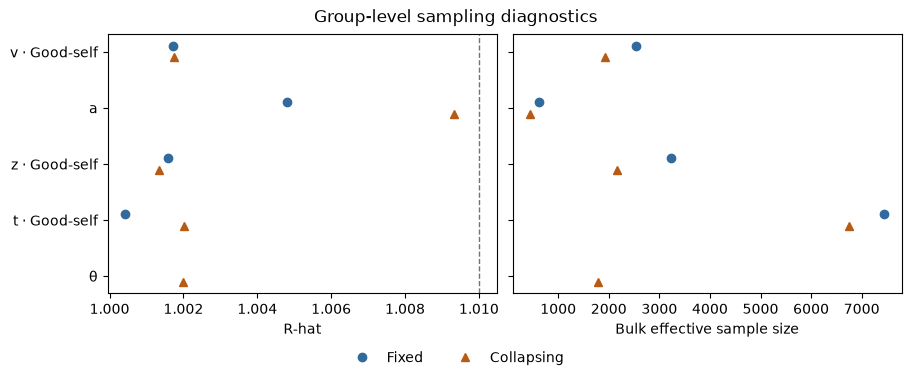

In [8]:
# 图中选取 Good-self 匹配条件的 v、z、t，以及共享的 a 和自由收缩角。
diagnostic_nodes = {
    "v_stim_sign:trial_condition[match_Good-self]": "v · Good-self",
    "a_Intercept": "a",
    "z_shape[Good-self]": "z · Good-self",
    "ndt_trial_condition[match_Good-self]": "t · Good-self",
    "theta": "θ",
}
positions = np.arange(len(diagnostic_nodes))
diagnostic_figure, axes = plt.subplots(1, 2, figsize=(9, 3.7), sharey=True, layout="constrained")
# 两栏分别对照链间一致性和主体有效样本量，固定角是常数。
for ax, statistic, label in zip(axes, ["r_hat", "ess_bulk"], ["R-hat", "Bulk effective sample size"]):
    values = diagnostics[statistic].unstack("model").loc[list(diagnostic_nodes)]
    ax.plot(values["Fixed"], positions - 0.10, "o", color="#316a9d", label="Fixed")
    ax.plot(values["Collapsing"], positions + 0.10, "^", color="#b65b15", label="Collapsing")
    ax.set_xlabel(label)
axes[0].axvline(1.01, color="0.45", ls="--", lw=1)  # R̂ 参考线。
axes[0].set_yticks(positions, list(diagnostic_nodes.values()))
axes[0].invert_yaxis()
diagnostic_figure.suptitle("Group-level sampling diagnostics")
diagnostic_figure.legend(
    *axes[0].get_legend_handles_labels(), loc="outside lower center", ncols=2, frameon=False,
)
plt.show()

### 4.3 逐链轨迹

每个模型叠画四条链。\(v,z\) 取 Good-self 实际匹配条件，\(a\) 跨条件共享，\(t\) 取各模型 \(\hat R\) 最高的组层条件。组层轨迹在原参数尺度作图，个体效应设为零。横轴为预热后保留的抽样次序。

In [9]:
# 在四种实际匹配条件上提取原参数尺度的组层抽样，保留链号与抽样顺序。
matching_shapes = (
    fit_trials.loc[fit_trials["match"].eq("match")]
    .drop_duplicates("shape")
    .set_index("shape", drop=False).loc[shape_order]
    .reset_index(drop=True)
)
group_draws = {}
for name, model in models.items():
    # 将个体偏移设为零，让 HSSM 给出原参数尺度上的组层位置。
    predicted = model.predict(
        idata=fits[name], data=matching_shapes, kind="response_params",
        include_group_specific=False, inplace=False,
    )
    posterior = predicted["posterior"].ds
    parameters = posterior[["v", "a", "z"]].assign(
        theta=fixed_theta if name == "Fixed" else posterior["theta"],
    )
    # 用形状名标注四行预测，使同次抽样的自我条件可以按名称配对。
    group_draws[name] = parameters.assign_coords(__obs__=shape_order).rename({"__obs__": "shape"})

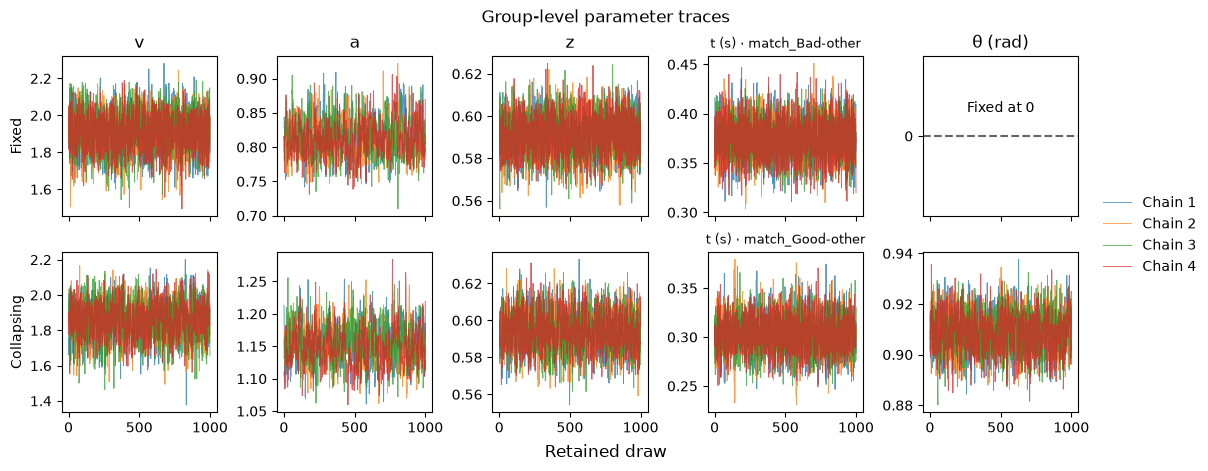

In [10]:
# 每行一个模型，每列一个参数。曲线按链绘制，横轴是预热后的抽样次序。
trace_nodes = {"v": "v", "a": "a", "z": "z", "t": "t (s)", "theta": "θ (rad)"}
trace_figure, axes = plt.subplots(2, 5, figsize=(12, 4.6), sharex=True, layout="constrained")
for row, (name, parameters) in enumerate(group_draws.items()):
    good_self = parameters.sel(shape="Good-self")
    axes[row, 0].set_ylabel(name)
    t_condition = sampling_summary.loc[name, "worst_group_t_condition"]
    t_location = fits[name]["posterior"]["ndt_trial_condition"]
    time_trace = t_lower + (t_upper - t_lower) * xr.apply_ufunc(
        expit, t_location.sel({t_location.dims[-1]: t_condition}),
    )
    for col, (node, label) in enumerate(trace_nodes.items()):
        ax = axes[row, col]
        if node == "t":
            ax.set_title(f"t (s) · {t_condition}", fontsize=9)
        elif row == 0:
            ax.set_title(label)
        # 固定模型的角度由定义给定，轴上用 θ = 0 的水平线表示。
        if name == "Fixed" and node == "theta":
            ax.axhline(fixed_theta, color="0.4", ls="--")
            ax.set(ylim=(-0.05, 0.05), yticks=[fixed_theta])
            ax.text(0.5, 0.65, "Fixed at 0", transform=ax.transAxes, ha="center")
            continue
        # 同一参数叠画各条链，方便查看它们是否长期停留在不同取值区间。
        trace = time_trace if node == "t" else good_self[node]
        for chain in trace.chain.values:
            values = trace.sel(chain=chain)
            ax.plot(values.draw + 1, values, lw=0.65, alpha=0.75, label=f"Chain {chain + 1}")
trace_figure.supxlabel("Retained draw")
trace_figure.suptitle("Group-level parameter traces")
trace_figure.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside right center", frameon=False)
plt.show()

# 保存采样诊断与链轨迹供拟合后的检查。
diagnostics.to_csv(outputs / "parameter_diagnostics.csv")
sampling_summary.to_csv(outputs / "sampling_summary.csv")
chain_summary.to_csv(outputs / "chain_diagnostics.csv")
diagnostic_figure.savefig(outputs / "group_sampling_diagnostics.pdf", bbox_inches="tight")
trace_figure.savefig(outputs / "trace_diagnostics.pdf", bbox_inches="tight")


### 4.4 被试条件参数与拟合数据 DIC

每条抽样保留被试偏移后，在原参数尺度计算对应的 \(v,a,z,t\)。表中诊断每条链最接近 \(RT=t\) 的程度。

按同一个窗口条件似然计算 \(D=-2\log L\)。\(p_D=\bar D-D(\bar\phi)\)，\(\mathrm{DIC}=\bar D+p_D\)。DIC 比较的是对已观测被试的条件拟合结果。采样诊断通过、且后验均值在似然支持内时报告 DIC。

[DIC 定义](https://doi.org/10.1111/1467-9868.00353)

In [11]:
# 提取每个被试与条件的原尺度后验，保留链、抽样、参数格三个维度。
core_parameters = ["v", "a", "z", "t"]
parameter_draws, angle_draws = {}, {}
for name, model in models.items():
    prediction = model.predict(
        idata=fits[name], data=parameter_cells, kind="response_params", inplace=False,
    )
    posterior = prediction["posterior"].ds.rename({"ndt": "t"})
    values = (
        posterior[core_parameters].to_array("parameter")
        .transpose("chain", "draw", "__obs__", "parameter").to_numpy()
    )
    parameter_draws[name] = values
    angle_draws[name] = (
        np.zeros(values.shape[:2]) if name == "Fixed" else posterior["theta"].values
    )


def trial_log_likelihood(rows, slots):
    # 用各试次的 RT、选择和对应的参数行计算窗口条件似然。
    rt = rows["rt"].to_numpy()
    choices = rows["response"].to_numpy()

    @jax.jit
    def score(parameters, angle):
        return conditional_log_density(
            rt, choices, slots, window_open, deadline, parameters, angle,
        )

    return score


# 按链汇总最小 RT−t。若后验处于可行域，拟合试次的差值始终为正。
fastest_by_cell = fit_trials.groupby(cell_keys, observed=True)["rt"].min()
fastest_rt = fastest_by_cell.loc[cell_positions.index].to_numpy()
support_rows = []
for name, values in parameter_draws.items():
    gaps = (fastest_rt - values[..., core_parameters.index("t")]).min(axis=-1)
    for chain, gap in enumerate(gaps, start=1):
        support_rows.append({
            "model": name, "chain": chain, "minimum_gap_ms": 1000 * gap.min(),
            "median_minimum_gap_ms": 1000 * np.median(gap),
        })
support_summary = pd.DataFrame(support_rows).set_index(["model", "chain"])
display(support_summary)

minimum_gap_ms  median_minimum_gap_ms
model      chain                                       
Fixed      1            6.067570              11.810738
           2            4.688514              11.841405
           3            5.846172              11.790853
           4            5.307931              11.972449
Collapsing 1           11.358104              23.151922
           2           10.962832              22.980390
           3           10.287548              23.550229
           4           12.614178              23.343628

In [12]:
# 在同一试次上为后验逐项计算两个似然，也保留桥采样的逐抽样似然比。
fit_likelihood = trial_log_likelihood(fit_trials, fit_slots)
total_fit_loglik = jax.jit(lambda parameters, angle: fit_likelihood(parameters, angle).sum())
batch_fit_loglik = jax.jit(jax.vmap(total_fit_loglik))
rng = np.random.default_rng(seed)


def score_batches(batch_score, samples, angles):
    for start in range(0, len(samples), score_batch_size):
        batch = slice(start, start + score_batch_size)
        yield np.asarray(batch_score(samples[batch], angles[batch]))


def evaluate_fit_draws(samples, angles):
    return np.concatenate(list(score_batches(batch_fit_loglik, samples, angles)))


dic_rows, log_ratios = [], {}
for name in models:
    row = {"model": name, "status": "sampling_diagnostics_failed"}
    if sampling_summary.loc[name, "comparison_ready"]:
        draws = parameter_draws[name]
        angles = angle_draws[name]
        samples = draws.reshape(-1, *draws.shape[2:])
        own_loglik = evaluate_fit_draws(samples, angles.ravel())
        if sampling_ok:
            # 固定模型的桥接抽样为每一轮附加一个从收缩角先验抽出的角度。
            if name == "Fixed":
                other = evaluate_fit_draws(samples, rng.uniform(*angle_bounds, size=len(samples)))
                log_ratios[name] = (other - own_loglik).reshape(angles.shape)
            else:
                other = evaluate_fit_draws(samples, np.zeros(len(samples)))
                log_ratios[name] = (own_loglik - other).reshape(angles.shape)
        mean_deviance = -2 * own_loglik.mean()
        deviance_at_mean = -2 * float(total_fit_loglik(samples.mean(axis=0), angles.mean()))
        if np.isfinite(deviance_at_mean):
            effective_parameters = mean_deviance - deviance_at_mean
            row.update(
                status="estimated", mean_deviance=mean_deviance, deviance_at_mean=deviance_at_mean,
                p_D=effective_parameters, DIC=mean_deviance + effective_parameters,
            )
        else:
            row.update(status="posterior_mean_outside_support", mean_deviance=mean_deviance)
    dic_rows.append(row)

dic = pd.DataFrame(dic_rows).set_index("model").reindex(
    columns=["status", "mean_deviance", "deviance_at_mean", "p_D", "DIC"],
)
display(dic.round(2))

,status,mean_deviance,deviance_at_mean,p_D,DIC
model,,,,,
Fixed,estimated,-9541.06,-10253.75,712.69,-8828.37
Collapsing,estimated,-11235.99,-11965.39,729.40,-10506.60


### 4.5 拟合数据的后验模型概率

两个模型的先验概率均为 0.5。直接桥采样为固定模型附加一个从收缩角先验独立抽出的角度，固定模型的似然仍按零角度计算。共同先验在比值中抵消。某个附加角度导致固定模型的抽样在收缩模型下不可行时，该抽样对相应桥权重的贡献为零。

先检查链诊断与两组对数似然比的重叠，再求 Bayes 因子。表中保留合并链、逐链结果、对数平均桥权重和两侧权重的有效样本量。两侧的权重有效样本量均达到 20 时才报告模型概率，合并链的概率还要求各链都通过桥接检查。

[直接桥采样](https://www3.stat.sinica.edu.tw/statistica/j6n4/j6n43/j6n43.htm)

In [13]:
def bridge_evidence(fixed, collapsing):
    """在两组后验间用对数域桥权重估计边际似然比。"""
    fixed, collapsing = np.ravel(fixed), np.ravel(collapsing)
    finite_fixed = fixed[np.isfinite(fixed)]
    # 附加角度可能使收缩模型的密度为零。固定侧的 −inf 仍参加权重计算。
    if np.isnan(fixed).any() or np.isposinf(fixed).any() or not np.isfinite(collapsing).all():
        return {"status": "invalid_log_ratio"}
    if not len(finite_fixed):
        return {"status": "no_shared_support", "overlapping_ranges": False}

    overlap = max(finite_fixed.min(), collapsing.min()) <= min(finite_fixed.max(), collapsing.max())
    if not overlap:
        return {"status": "ranges_disjoint", "overlapping_ranges": False}

    log_sample_ratio = np.log(collapsing.size / fixed.size)

    def log_weights(log_bf):
        return (
            log_expit(fixed - log_bf + log_sample_ratio),
            log_expit(log_bf - collapsing - log_sample_ratio),
        )

    def balance(log_bf):
        fixed_weight, collapsing_weight = log_weights(log_bf)
        return logsumexp(fixed_weight) - logsumexp(collapsing_weight)

    # 固定后验中收缩密度为零的样本会改变有效区间，先建立平衡方程的根区间。
    padding = 1 + np.log(fixed.size + collapsing.size)
    lower = min(finite_fixed.min(), collapsing.min()) - padding
    upper = max(finite_fixed.max(), collapsing.max()) + padding
    log_bf = brentq(balance, lower, upper)
    fixed_weights, collapsing_weights = log_weights(log_bf)
    fixed_total = logsumexp(fixed_weights)
    collapsing_total = logsumexp(collapsing_weights)
    fixed_ess = np.exp(2 * fixed_total - logsumexp(2 * fixed_weights))
    collapsing_ess = np.exp(2 * collapsing_total - logsumexp(2 * collapsing_weights))
    result = {
        "status": "insufficient_bridge_ess", "overlapping_ranges": True,
        "log_mean_bridge_weight": fixed_total - np.log(fixed.size),
        "fixed_bridge_ess": fixed_ess, "collapsing_bridge_ess": collapsing_ess,
    }
    if min(fixed_ess, collapsing_ess) >= 20:
        result.update(
            status="estimated", log_BF_collapsing_fixed=log_bf,
            P_Fixed=expit(-log_bf), P_Collapsing=expit(log_bf),
        )
    return result


# 同时报告合并后验与逐链估计，便于检查桥接结果对链的依赖。
n_chains = fits["Fixed"]["posterior"].sizes["chain"]
labels = ["all_chains", *[f"chain_{i}" for i in range(1, n_chains + 1)]]
if sampling_ok:
    fixed_ratios, collapsing_ratios = log_ratios["Fixed"], log_ratios["Collapsing"]
    by_chain = [
        bridge_evidence(fixed, collapsing) for fixed, collapsing in zip(fixed_ratios, collapsing_ratios)
    ]
    pooled = bridge_evidence(fixed_ratios, collapsing_ratios)
    if pooled["status"] == "estimated" and any(row["status"] != "estimated" for row in by_chain):
        pooled.update(
            status="bridge_not_supported_by_each_chain",
            log_BF_collapsing_fixed=np.nan, P_Fixed=np.nan, P_Collapsing=np.nan,
        )
    evidence_rows = [pooled, *by_chain]
else:
    evidence_rows = [{"status": "sampling_diagnostics_failed"} for _ in labels]

model_probabilities = pd.DataFrame(evidence_rows, index=labels).reindex(columns=[
    "status", "log_BF_collapsing_fixed", "P_Fixed", "P_Collapsing", "overlapping_ranges",
    "log_mean_bridge_weight", "fixed_bridge_ess", "collapsing_bridge_ess",
])
display(model_probabilities)

,status,log_BF_collapsing_fixed,P_Fixed,P_Collapsing,overlapping_ranges,log_mean_bridge_weight,fixed_bridge_ess,collapsing_bridge_ess
all_chains,ranges_disjoint,NaN,NaN,NaN,False,NaN,NaN,NaN
chain_1,ranges_disjoint,NaN,NaN,NaN,False,NaN,NaN,NaN
chain_2,ranges_disjoint,NaN,NaN,NaN,False,NaN,NaN,NaN
chain_3,ranges_disjoint,NaN,NaN,NaN,False,NaN,NaN,NaN
chain_4,ranges_disjoint,NaN,NaN,NaN,False,NaN,NaN,NaN


## 5. 留出预测与模型比较

### 5.1 按作答窗口预测选择和 RT

每条链均匀选取最多 50 次抽样。按留出的被试和条件，在作答窗口内用等宽时间格计算两种选择的概率质量，再抽取选择和 RT。按链报告预估的窗口内作答概率。

In [14]:
@jax.jit
def predictive_grid(parameters, theta, openings, deadlines, fractions):
    # 用同一首达密度和作答窗口，对两种选择的时间格中点评分。
    v, a, z, t = parameters.T
    start, end = response_time_limits(openings, deadlines, a, t, theta)
    widths = end - start
    rt = start[:, None, None] + widths[:, None, None] * fractions
    log_density = angle_log_density(
        rt, jnp.array([-1, 1])[None, :, None], v[:, None, None], a[:, None, None],
        z[:, None, None], t[:, None, None], theta,
    )
    return start, widths, log_density


# 两个模型共用留出试次的被试条件分组和作答窗口。
heldout_cells, cell_ids, cell_counts = np.unique(
    heldout_slots, return_inverse=True, return_counts=True,
)
rows_by_cell = np.split(np.argsort(cell_ids), cell_counts.cumsum()[:-1])
heldout_labels = heldout_trials[["match", "shape"]]


def predict_heldout(name, draws_per_chain=50, bins=1024):
    draws, angles = parameter_draws[name], angle_draws[name]
    selected = np.linspace(0, draws.shape[1] - 1, min(draws_per_chain, draws.shape[1]), dtype=int)
    fractions = (np.arange(bins) + 0.5) / bins
    rng = np.random.default_rng(seed)
    rt_choices = np.empty((draws.shape[0], len(selected), len(heldout_labels), 2))
    masses = np.empty(rt_choices.shape[:2])

    for chain, column in np.ndindex(rt_choices.shape[:2]):
        draw = selected[column]
        start, widths, log_density = map(np.asarray, predictive_grid(
            draws[chain, draw, heldout_cells], angles[chain, draw],
            window_open[heldout_cells], deadline[heldout_cells], fractions,
        ))
        if np.any(widths <= 0):
            raise ValueError("该后验抽样的部分试次条件没有有效作答窗口。")

        # 两个按键共用归一化分母。窗口概率按各被试条件的留出试次数加权。
        log_density = log_density.reshape(len(heldout_cells), 2 * bins)
        log_total = logsumexp(log_density, axis=1)
        cdf = np.cumsum(np.exp(log_density - log_total[:, None]), axis=1)
        cdf /= cdf[:, -1:]
        masses[chain, column] = np.average(np.exp(log_total) * (widths / bins), weights=cell_counts)

        # 每条试次按对应被试条件的分布抽时间格，再在格内均匀抽取 RT。
        for cell, rows in enumerate(rows_by_cell):
            sampled_bin = np.searchsorted(cdf[cell], rng.random(len(rows)), side="right")
            position = (sampled_bin % bins + rng.random(len(rows))) / bins
            rt_choices[chain, column, rows, 0] = start[cell] + position * widths[cell]
            rt_choices[chain, column, rows, 1] = np.where(sampled_bin < bins, -1, 1)

    frame = pd.DataFrame(rt_choices.reshape(-1, 2), columns=["rt", "response"])
    labels = heldout_labels.iloc[np.tile(np.arange(len(heldout_labels)), masses.size)]
    window_probability = pd.Series(
        100 * masses.mean(axis=1), index=pd.RangeIndex(1, len(masses) + 1, name="chain"),
        name="predicted_window_pct",
    )
    return frame.join(labels.reset_index(drop=True)).assign(source=name), window_probability


observed = heldout_trials[["match", "shape", "rt", "response"]].assign(source="Observed")
predictions = {name: predict_heldout(name) for name in models}
prediction_data = pd.concat([observed, *(frame for frame, _ in predictions.values())], ignore_index=True)
window_diagnostics = pd.concat(
    {name: mass for name, (_, mass) in predictions.items()}, names=["model", "chain"],
).sort_index().to_frame()
del predictions  # 合并表与窗口摘要已就绪，释放各模型的模拟明细。
display(window_diagnostics.round(2))

predicted_window_pct
model      chain                      
Collapsing 1                     97.28
           2                     97.30
           3                     97.31
           4                     97.34
Fixed      1                     76.89
           2                     76.86
           3                     76.81
           4                     76.92

### 5.2 慢反应与选择的预测误差

在八种试次条件及两种实际选择下，计算 RT 的第 90 百分位误差，单位为毫秒。按八种条件计算 Match 选择率误差，单位为百分点。两项均比较同一批留出作答。对应的模型分差使用固定边界误差减去收缩边界误差。

In [15]:
# 汇总各条件与实际选择的反应时第 90 百分位，单位为毫秒。
conditions = ["match", "shape"]
sources = ["Observed", *models]
rt_q90 = (
    prediction_data.groupby([*conditions, "response", "source"], observed=True)["rt"]
    .quantile(0.90).mul(1000)
    .unstack("source").reindex(columns=sources)
)

# 在每个条件下计算实际或模拟选择 Match 的比例。
match_table = (
    prediction_data.assign(match_choice=prediction_data["response"].eq(1))
    .groupby([*conditions, "source"], observed=True)["match_choice"].mean()
    .unstack("source").reindex(columns=sources)
)

# 在同一条件格内先做预测减实测，再取绝对值并等权平均。选择率误差换算为百分点。
scored_models = list(models)
rt_error = rt_q90[scored_models].sub(rt_q90["Observed"], axis=0)
choice_error = match_table[scored_models].sub(match_table["Observed"], axis=0)
prediction_scores = pd.DataFrame({
    "rt_q90_mae_ms": rt_error.abs().mean(skipna=False),
    "match_choice_mae_pp": 100 * choice_error.abs().mean(skipna=False),
}).rename_axis("model")

# 表中差值为“固定误差 − 收缩误差”，正值表示收缩模型误差较小。
model_comparison = prediction_scores.T.rename_axis(index="metric", columns=None)
model_comparison["fixed_minus_collapsing"] = model_comparison["Fixed"] - model_comparison["Collapsing"]
model_comparison["comparison_ready"] = sampling_ok
display(model_comparison.round(3))
display(rt_q90.round(1))
display(match_table.round(3))

,Fixed,Collapsing,fixed_minus_collapsing,comparison_ready
metric,,,,
rt_q90_mae_ms,83.278,56.696,26.582,True
match_choice_mae_pp,2.204,1.728,0.476,True


source                        Observed  Fixed  Collapsing
match    shape      response                             
match    Bad-other  -1.0         901.7  987.7       978.7
                     1.0         871.5  969.1       914.0
         Bad-self   -1.0         877.5  994.7       982.6
                     1.0         893.8  973.6       928.3
         Good-other -1.0         905.8  990.6       982.0
                     1.0         885.7  946.9       885.8
         Good-self  -1.0         832.3  993.7       987.5
                     1.0         814.9  909.0       844.5
mismatch Bad-other  -1.0         907.1  976.8       928.4
                     1.0         891.8  974.2       985.1
         Bad-self   -1.0         905.5  988.3       944.3
                     1.0         976.6  977.4       984.0
         Good-other -1.0         922.8  983.0       933.3
                     1.0         890.0  972.5       977.0
         Good-self  -1.0         906.3  986.4       928.8
                     1.0         849.2  941.1       955.5

source               Observed  Fixed  Collapsing
match    shape                                  
match    Bad-other      0.820  0.854       0.832
         Bad-self       0.805  0.822       0.802
         Good-other     0.836  0.860       0.835
         Good-self      0.888  0.945       0.932
mismatch Bad-other      0.113  0.129       0.152
         Bad-self       0.171  0.169       0.191
         Good-other     0.188  0.183       0.203
         Good-self      0.188  0.168       0.189

### 5.3 慢反应与 Match 选择率的留出对照

每行对应一种刺激状态和形状。前两栏展示分别选择 Match 和 Mismatch 时的 RT 第 90 百分位，第三栏展示 Match 选择比例。三种符号分别表示实测值、固定边界预测和收缩边界预测。 同色线段在实际匹配和实际不匹配两组内分别连接四种形状，便于追踪同一来源的数值。纵轴按实验类别排列。

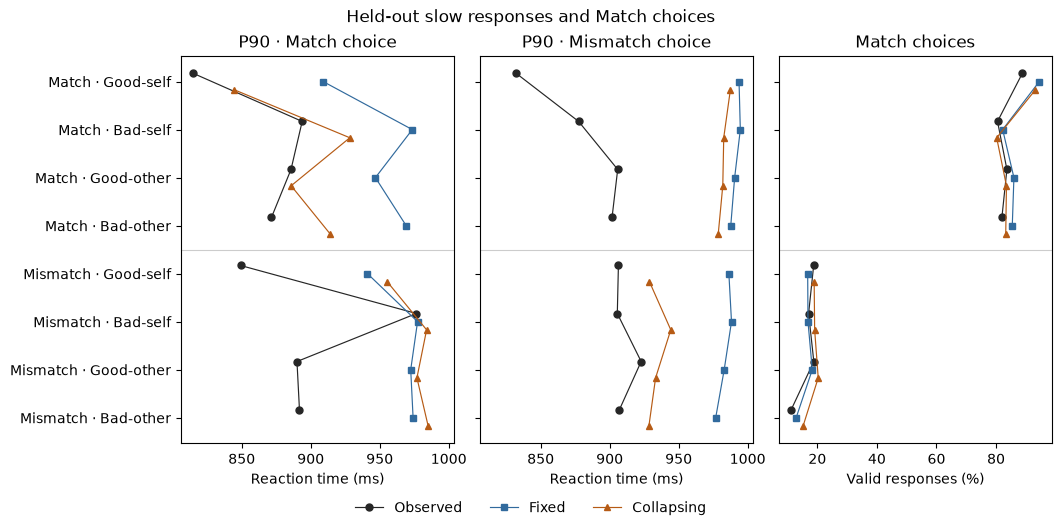

In [16]:
# 将八种条件的慢反应和 Match 选择率与实测值逐项对照。
condition_order = pd.MultiIndex.from_product(
    [["match", "mismatch"], shape_order], names=["match", "shape"],
)
panels = [
    (rt_q90.xs(1, level="response"), "P90 · Match choice", "Reaction time (ms)"),
    (rt_q90.xs(-1, level="response"), "P90 · Mismatch choice", "Reaction time (ms)"),
    (100 * match_table, "Match choices", "Valid responses (%)"),
]
profile_figure, axes = plt.subplots(1, 3, figsize=(10.5, 5.2), sharey=True, layout="constrained")
axes[1].sharex(axes[0])
positions = np.arange(len(condition_order))
# 同一条件内三种来源略微错开，三栏分别读作 Match P90、Non-match P90 和 Match 比例。
series = [
    ("Observed", -0.17, "0.15", "o"),
    ("Fixed", 0, "#316a9d", "s"),
    ("Collapsing", 0.17, "#b65b15", "^"),
]
for ax, (table, title, xlabel) in zip(axes, panels):
    values = table.loc[condition_order]
    for source, offset, color, marker in series:
        # 沿条件列表分别连接匹配和不匹配刺激中的四个点。
        for stimulus in ("match", "mismatch"):
            group_rows = values.index.get_level_values("match") == stimulus
            ax.plot(
                values.loc[group_rows, source], positions[group_rows] + offset,
                color=color, marker=marker, markersize=5, linewidth=0.85,
                label=source if stimulus == "match" else None,
            )
    ax.axhline(3.5, color="0.8", lw=0.8)  # 前四行实际匹配，后四行实际不匹配。
    ax.set(title=title, xlabel=xlabel)
axes[0].set_yticks(positions, [f"{match.title()} · {shape}" for match, shape in condition_order])
axes[0].invert_yaxis()
profile_figure.suptitle("Held-out slow responses and Match choices")
profile_figure.legend(
    *axes[0].get_legend_handles_labels(), loc="outside lower center", ncols=3, frameon=False,
)
plt.show()

### 5.4 分条件的选择与反应时联合密度

四列为四种形状，四行为刺激匹配状态与实际按键的组合。实测与两模型共用 10 毫秒分箱。在同一刺激状态、形状和数据来源内，两种按键共用全部有效作答数作为分母。各条曲线的面积对应该条件下选择该按键的比例。

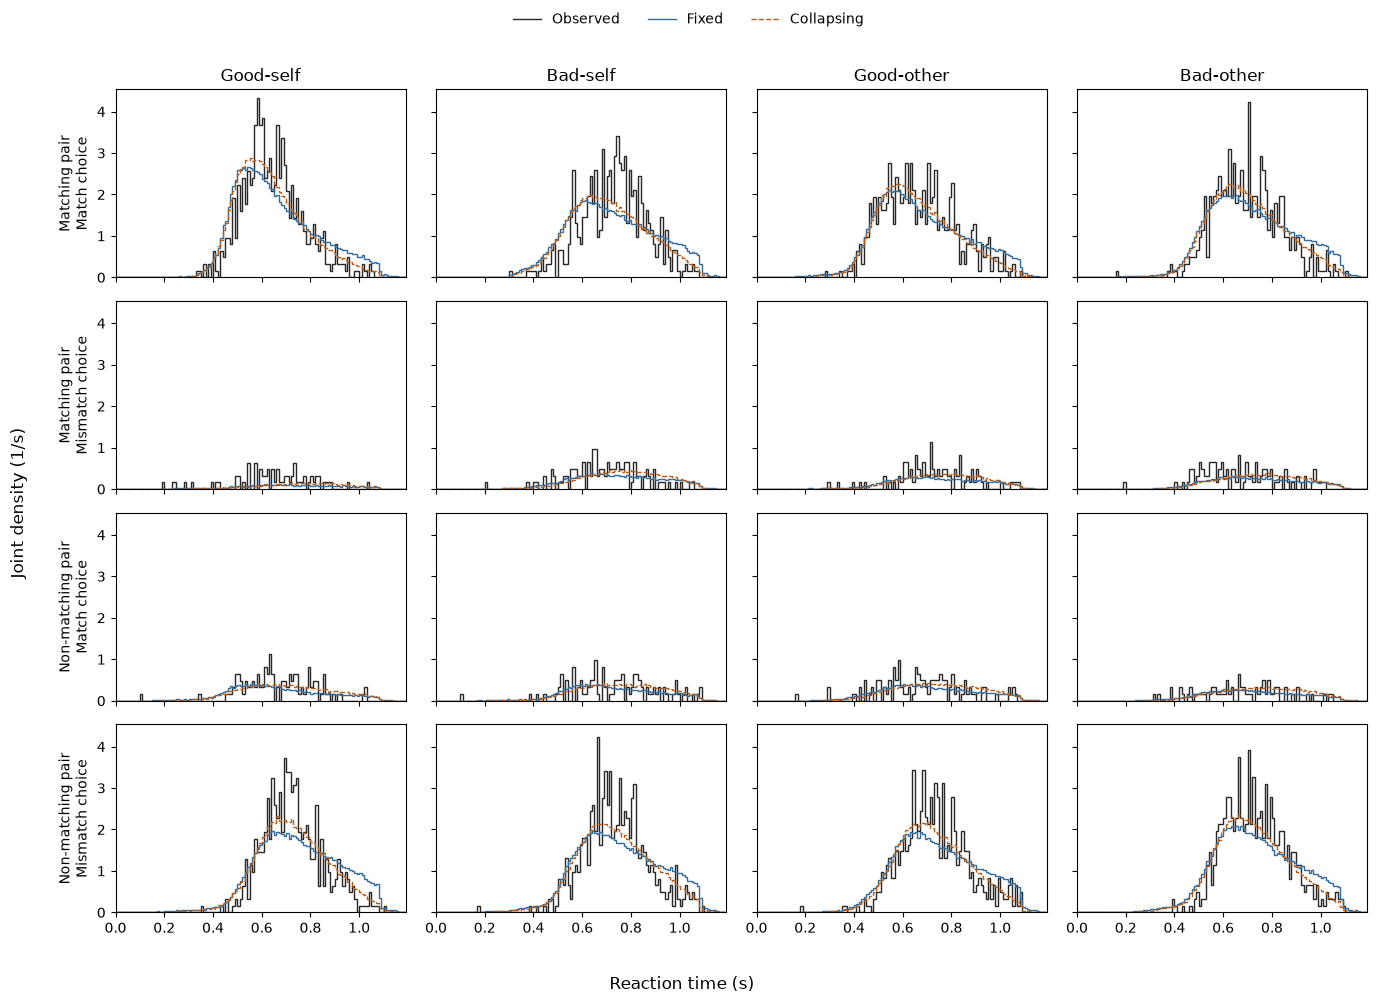

In [17]:
# 绘制四种形状在两种刺激状态和两种实际选择下的 选择与 RT 联合密度。
response_rows = [
    ("match", 1, "Matching pair\nMatch choice"),
    ("match", -1, "Matching pair\nMismatch choice"),
    ("mismatch", 1, "Non-matching pair\nMatch choice"),
    ("mismatch", -1, "Non-matching pair\nMismatch choice"),
]
styles = {"Observed": ("0.15", "-"), "Fixed": ("#316a9d", "-"), "Collapsing": ("#b65b15", "--")}
bin_width = 0.01  # 每个时间箱宽 10 毫秒，实测和两模型共用。
rt_limit = np.ceil(heldout_trials["deadline"].max() / bin_width) * bin_width
rt_bins = np.arange(round(rt_limit / bin_width) + 1) * bin_width
# 同一刺激状态、形状和来源内，两种按键共用全部有效作答数。
condition_groups = prediction_data.groupby(["match", "shape", "source"], observed=True)
density_figure, axes = plt.subplots(4, 4, figsize=(14, 10), sharex=True, sharey=True)

for row, (match, response, label) in enumerate(response_rows):
    axes[row, 0].set_ylabel(label)
    for column, shape in enumerate(shape_order):
        ax = axes[row, column]
        for source, (color, linestyle) in styles.items():
            trials_in_condition = condition_groups.get_group((match, shape, source))
            selected_rt = trials_in_condition.loc[trials_in_condition["response"].eq(response), "rt"]
            counts = np.histogram(selected_rt, bins=rt_bins)[0]
            density = counts / (len(trials_in_condition) * np.diff(rt_bins))
            ax.stairs(density, rt_bins, color=color, linestyle=linestyle, label=source)
        if row == 0:
            ax.set_title(shape)

axes[0, 0].set_xlim(0, rt_limit)
density_figure.supxlabel("Reaction time (s)")
density_figure.supylabel("Joint density (1/s)")
density_figure.legend(
    *axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=3, frameon=False,
)
density_figure.tight_layout(rect=(0.02, 0.02, 1, 0.95))
plt.show()

### 5.5 主指标 · 留出联合对数预测密度

对每条留出试次，在窗口条件似然下先对后验密度求平均，再取对数。使用相同被试、相同试次的配对分差 \(\mathrm{LPD}_{\mathrm{收缩}}-\mathrm{LPD}_{\mathrm{固定}}\)，正值表示对这批作答的留出预测分数更高。按被试成对重抽给出平均分差的 95% 区间。

同时列出每条链的预测分数以及后验样本给出零预测密度的试次数。存在零预测密度或采样未通过时，配对区间留空。

In [18]:
# 逐试次评分使用拟合时的同一窗口条件密度。
heldout_likelihood = trial_log_likelihood(heldout_trials, heldout_slots)
batch_heldout_loglik = jax.jit(jax.vmap(heldout_likelihood))
pointwise_lpd = heldout_trials[["participant_id", "trial_condition", "rt", "response"]].copy()
chain_lpd_rows = []
for name in models:
    values, angles = parameter_draws[name], angle_draws[name]
    chain_log_sums = []
    for chain in range(values.shape[0]):
        log_sum = np.full(len(heldout_trials), -np.inf)
        for log_likelihood in score_batches(batch_heldout_loglik, values[chain], angles[chain]):
            log_sum = np.logaddexp(log_sum, logsumexp(log_likelihood, axis=0))
        chain_log_sums.append(log_sum)
        chain_lpd = log_sum - np.log(values.shape[1])
        chain_lpd_rows.append({
            "model": name, "chain": chain + 1, "mean_lpd": chain_lpd.mean(),
            "trials_with_zero_density": int(np.isneginf(chain_lpd).sum()),
        })

    # 先在所有后验抽样上平均密度，再取对数。
    pointwise_lpd[name] = logsumexp(chain_log_sums, axis=0) - np.log(angles.size)

heldout_lpd_by_chain = pd.DataFrame(chain_lpd_rows)
scores = pointwise_lpd[list(models)]
zero_density = np.isneginf(scores).sum()
scores_finite = np.isfinite(scores.to_numpy()).all()
heldout_lpd = pd.DataFrame({
    "trials": len(scores), "total_lpd": scores.sum(), "mean_lpd": scores.mean(),
    "trials_with_zero_density": zero_density, "comparison_ready": sampling_ok and scores_finite,
}).rename_axis("model")

# 单独记录采样状态和零密度试次数，配对比较需要诊断通过与有限分数。
issues = []
if not sampling_ok:
    issues.append("sampling_diagnostics_failed")
if not scores_finite:
    issues.append("nonfinite_predictive_density")
comparison = {
    "status": ", ".join(issues) if issues else "estimated",
    "zero_density_fixed": zero_density["Fixed"],
    "zero_density_collapsing": zero_density["Collapsing"],
}
if scores_finite:
    pointwise_lpd["collapsing_minus_fixed"] = pointwise_lpd["Collapsing"] - pointwise_lpd["Fixed"]
    by_subject = pointwise_lpd.groupby("participant_id")["collapsing_minus_fixed"].agg(["sum", "size"])
    score, n_trials = by_subject["sum"].to_numpy(), by_subject["size"].to_numpy()
    comparison.update(total_delta_lpd=score.sum(), mean_delta_lpd=score.sum() / n_trials.sum())
    if sampling_ok:
        rng = np.random.default_rng(seed)
        subjects = rng.integers(0, len(by_subject), size=(4000, len(by_subject)))
        bootstrap_mean = score[subjects].sum(axis=1) / n_trials[subjects].sum(axis=1)
        lower, upper = np.quantile(bootstrap_mean, [0.025, 0.975])
        comparison.update(bootstrap_95_lower=lower, bootstrap_95_upper=upper)

heldout_lpd_difference = pd.DataFrame([comparison]).reindex(columns=[
    "status", "zero_density_fixed", "zero_density_collapsing",
    "total_delta_lpd", "mean_delta_lpd", "bootstrap_95_lower", "bootstrap_95_upper",
])
display(heldout_lpd.round(3))
display(heldout_lpd_difference.round(3))

,trials,total_lpd,mean_lpd,trials_with_zero_density,comparison_ready
model,,,,,
Fixed,4929,-inf,-inf,7,False
Collapsing,4929,-inf,-inf,3,False


,status,zero_density_fixed,zero_density_collapsing,total_delta_lpd,mean_delta_lpd,bootstrap_95_lower,bootstrap_95_upper
0,nonfinite_predictive_density,7,3,NaN,NaN,NaN,NaN


## 6. 匹配试次的组层参数

### 6.1 Good-self 与 Bad-self 参数对照

用实际匹配试次的组层漂移率和起点比较 Good-self 与 Bad-self。令个体效应为零，用共同噪声尺度报告漂移率差。

汇总两个差值和收缩角 \(\theta\) 的后验均值和 95% 等尾可信区间。

点图使用同一张汇总表。区间反映保留抽样的分布，参数表同时给出逐链结果与采样状态。

In [19]:
# 同一次抽样内配对 Good-self 与 Bad-self 的组层参数。
contrasts = {}
parameter_rows = []
for name, parameters in group_draws.items():
    contrasts[name] = (
        parameters[["v", "z"]].sel(shape="Good-self")
        - parameters[["v", "z"]].sel(shape="Bad-self")
    )
    difference = contrasts[name]
    for label, draws in {
        "v(Good-self) - v(Bad-self)": difference["v"].values,
        "z(Good-self) - z(Bad-self)": difference["z"].values,
        "theta": parameters["theta"].broadcast_like(difference["v"]).values,
    }.items():
        groups = {"all_chains": draws}
        groups.update({f"chain_{index}": row for index, row in enumerate(draws, start=1)})
        for chain, values in groups.items():
            lower, upper = np.quantile(values, [0.025, 0.975])
            parameter_rows.append({
                "model": name, "parameter": label, "chain": chain, "mean": np.mean(values),
                "lower_95": lower, "upper_95": upper,
                "comparison_ready": sampling_summary.loc[name, "comparison_ready"],
            })

parameter_by_chain = pd.DataFrame(parameter_rows)
parameter_summary = parameter_by_chain.query("chain == 'all_chains'").set_index(["model", "parameter"])
display(parameter_summary.round(3))

chain   mean  lower_95  upper_95  \
model      parameter                                                           
Fixed      v(Good-self) - v(Bad-self)  all_chains  0.884     0.544     1.216   
           z(Good-self) - z(Bad-self)  all_chains  0.056     0.030     0.083   
           theta                       all_chains  0.000     0.000     0.000   
Collapsing v(Good-self) - v(Bad-self)  all_chains  0.758     0.433     1.088   
           z(Good-self) - z(Bad-self)  all_chains  0.058     0.026     0.087   
           theta                       all_chains  0.909     0.893     0.924   

                                       comparison_ready  
model      parameter                                     
Fixed      v(Good-self) - v(Bad-self)              True  
           z(Good-self) - z(Bad-self)              True  
           theta                                   True  
Collapsing v(Good-self) - v(Bad-self)              True  
           z(Good-self) - z(Bad-self)              True  
           theta                                   True

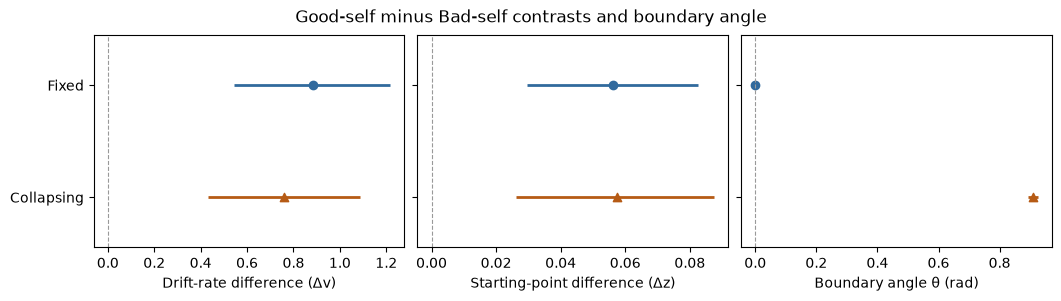

In [20]:
# 对照两个模型的参数差值和收缩角，点为后验均值，线为 95% 等尾可信区间。
parameters_to_plot = [
    ("v(Good-self) - v(Bad-self)", "Drift-rate difference (Δv)"),
    ("z(Good-self) - z(Bad-self)", "Starting-point difference (Δz)"),
    ("theta", "Boundary angle θ (rad)"),
]
interval_figure, axes = plt.subplots(
    1, 3, figsize=(10.5, 2.9), sharey=True, layout="constrained",
)
model_styles = [("Fixed", "#316a9d", "o"), ("Collapsing", "#b65b15", "^")]
for ax, (parameter, label) in zip(axes, parameters_to_plot):
    # Δv、Δz 的零线表示两种自我条件相同，θ 的零线表示固定边界。
    ax.axvline(0, color="0.6", ls="--", lw=0.8)
    for row, (name, color, marker) in enumerate(model_styles):
        estimate = parameter_summary.loc[(name, parameter)]
        ax.hlines(row, estimate["lower_95"], estimate["upper_95"], color=color, lw=2)
        ax.scatter(estimate["mean"], row, color=color, marker=marker)
    ax.set_xlabel(label)
axes[0].set_yticks([0, 1], list(models))
axes[0].set_ylim(1.45, -0.45)
interval_figure.suptitle("Good-self minus Bad-self contrasts and boundary angle")
plt.show()

### 6.2 四种形状的漂移率后验

左右两栏分别显示固定与收缩模型在实际匹配试次上的组层 \(v\)。每条曲线对应一种形状。合并四条链的参数图需结合第 4 节的诊断判断。

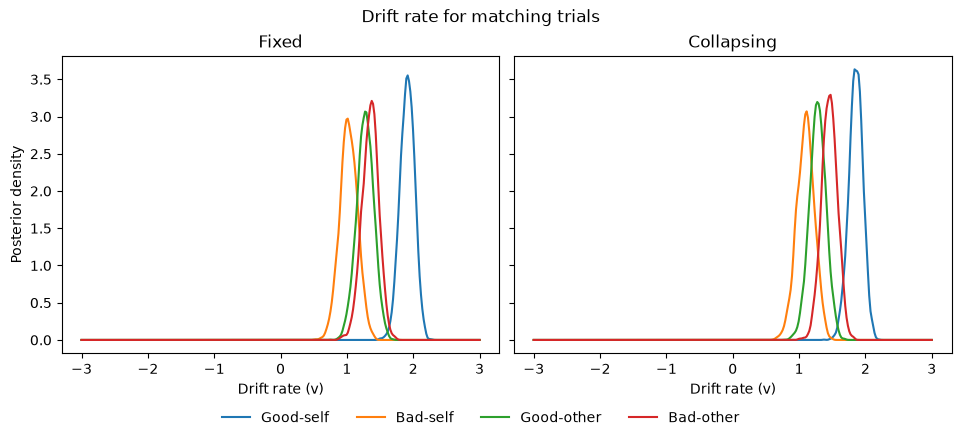

In [21]:
# 绘制两个模型在四种形状下的漂移率后验密度。
drift_grid = np.linspace(-3, 3, 300)  # ANGLE 漂移率的取值范围。
drift_figure, axes = plt.subplots(
    1, 2, figsize=(9.5, 4.3), sharex=True, sharey=True, layout="constrained",
)
for ax, (name, parameters) in zip(axes, group_draws.items()):
    # 将链和抽样合并为样本轴，四列各对应一种形状的匹配漂移。
    drift = parameters["v"].stack(sample=("chain", "draw")).transpose("sample", "shape").to_pandas()
    drift.plot.kde(ax=ax, ind=drift_grid, legend=False)
    ax.set(title=name, xlabel="Drift rate (v)")
axes[0].set_ylabel("Posterior density")
drift_figure.suptitle("Drift rate for matching trials")
drift_figure.legend(
    *axes[0].get_legend_handles_labels(), loc="outside lower center", ncols=4, frameon=False,
)
plt.show()

### 6.3 四种形状的起点

点为各形状的组层起点后验均值，横线为 95% 等尾可信区间，虚线为中性起点 \(z=0.5\)。

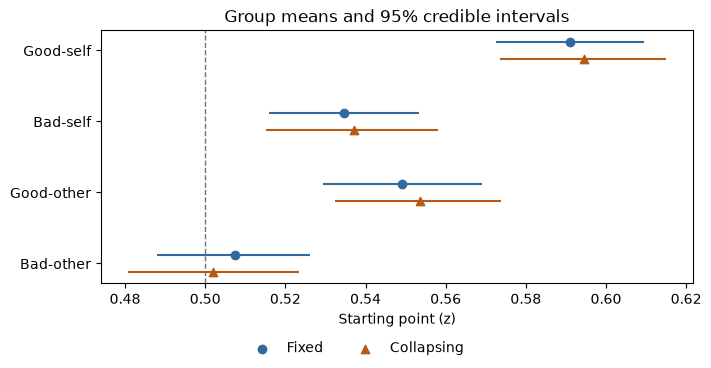

In [22]:
# 对照四种形状在两个模型下的起点均值及 95% 可信区间。
z_figure, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
positions = np.arange(len(shape_order))
ax.axvline(0.5, color="0.45", ls="--", lw=1)  # 两条起始边界的中点。
model_styles = [("Fixed", -0.12, "#316a9d", "o"), ("Collapsing", 0.12, "#b65b15", "^")]
for name, offset, color, marker in model_styles:
    z = group_draws[name]["z"]
    # 对每种形状汇总四条链，点和区间保留在相对起点的 0–1 尺度上。
    interval = z.quantile([0.025, 0.975], dim=["chain", "draw"]).values
    ax.hlines(positions + offset, interval[0], interval[1], color=color)
    ax.scatter(z.mean(["chain", "draw"]), positions + offset, color=color, marker=marker, label=name)
ax.set_yticks(positions, shape_order)
ax.invert_yaxis()
ax.set(xlabel="Starting point (z)", title="Group means and 95% credible intervals")
z_figure.legend(*ax.get_legend_handles_labels(), loc="outside lower center", ncols=2, frameon=False)
plt.show()

### 6.4 自我条件的起点差值

每个模型使用同一次抽样的 \(z_{\mathrm{Good-self}}-z_{\mathrm{Bad-self}}\)，每栏用相同的分箱绘制差值密度，虚线为零差值。

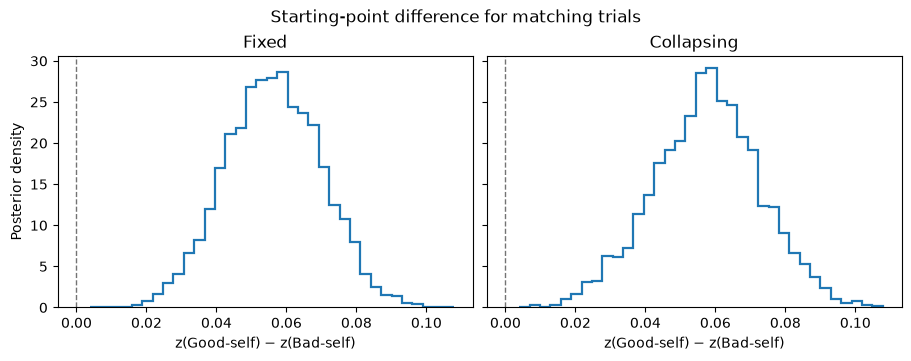

In [23]:
# 展示 Good-self 减 Bad-self 的起点差值分布。
z_differences = {name: difference["z"].values.ravel() for name, difference in contrasts.items()}
# 用两模型的差值抽样共同确定箱边界，使左右面板的密度形状可以直接对照。
bins = np.histogram_bin_edges(np.concatenate(list(z_differences.values())), bins=35)
contrast_figure, axes = plt.subplots(
    1, 2, figsize=(9, 3.5), sharex=True, sharey=True, layout="constrained",
)
for ax, (name, draws) in zip(axes, z_differences.items()):
    ax.hist(draws, bins=bins, density=True, histtype="step", lw=1.6)
    ax.axvline(0, color="0.45", ls="--", lw=1)
    ax.set(title=name, xlabel="z(Good-self) − z(Bad-self)")
axes[0].set_ylabel("Posterior density")
contrast_figure.suptitle("Starting-point difference for matching trials")
plt.show()

## 7. 保存结果

第 4 节先保存逐链后验、NUTS 诊断和轨迹。留出联合评分、分条件预测、模型比较和参数对照保存到 `../outputs/collapsing/m2_centered_ndt/`。

In [24]:
# 保存作答窗口、非决策时间支持与拟合数据的模型比较。
support_summary.to_csv(outputs / "nondecision_time_support.csv")
trials[["participant_id", "window_open", "deadline"]].drop_duplicates().to_csv(
    outputs / "response_windows.csv", index=False,
)
dic.to_csv(outputs / "conditional_dic.csv")
model_probabilities.to_csv(outputs / "posterior_model_probabilities.csv", index_label="chains")

# 保存留出试次逐条联合评分、每模型汇总和行为预测误差。
pointwise_lpd.to_csv(outputs / "heldout_log_density_trials.csv", index=False)
heldout_lpd.to_csv(outputs / "heldout_log_density.csv")
heldout_lpd_by_chain.to_csv(outputs / "heldout_log_density_by_chain.csv", index=False)
heldout_lpd_difference.to_csv(outputs / "heldout_log_density_difference.csv", index=False)
window_diagnostics.to_csv(outputs / "predicted_window_probability.csv")
model_comparison.to_csv(outputs / "heldout_model_comparison.csv")

# 保存按实际选择拆分的反应时 P90，以及各条件的 Match 选择率。
rt_by_choice = rt_q90.reset_index()
rt_by_choice["choice"] = rt_by_choice["response"].map({1: "Match", -1: "Mismatch"})
rt_by_choice.to_csv(outputs / "heldout_rt_q90.csv", index=False)
match_table.to_csv(outputs / "heldout_match_choice.csv")

# 参数表给出两项 Good-self − Bad-self 差值及收缩角。
parameter_by_chain.to_csv(outputs / "parameter_posterior_by_chain.csv", index=False)

# 保存留出行为预测和组层参数图。
density_figure.savefig(outputs / "heldout_rt_density_by_condition.pdf", bbox_inches="tight")
profile_figure.savefig(outputs / "heldout_slow_rt_and_rates.pdf", bbox_inches="tight")
drift_figure.savefig(outputs / "matching_drift_posterior.pdf", bbox_inches="tight")
z_figure.savefig(outputs / "z_by_condition.pdf", bbox_inches="tight")
contrast_figure.savefig(outputs / "z_self_contrast.pdf", bbox_inches="tight")
interval_figure.savefig(outputs / "parameter_intervals.pdf", bbox_inches="tight")